# 08 · Insights de negócio para a cafeicultura paulista

**Coffee Big Data Intelligence**

> **Aviso central:** este notebook **traduz** os resultados técnicos em respostas de negócio. Cada resposta traz seu **grau de confiança** e o que **não** se pode concluir. Todos os dados são **estimativas oficiais** (PAM/IBGE, CONAB) e clima de grade (~55 km): servem para **orientar perguntas**, não para decidir sozinhos um investimento.

## As quatro perguntas do projeto
1. **Quais regiões apresentam maior produtividade de café (arábica)?**
2. **Como a produção evoluiu?**
3. **Qual a relação entre clima e produtividade?**
4. **É possível prever a produção de uma região com dados históricos?**

Depois: aritmética de cenários (sensibilidade a produtividade e preço), recomendações e limitações.

**Escopo:** café **arábica**, estado de São Paulo (UF 35). Arábica e conilon **não são misturados** (a PAM só separa as espécies a partir de 2012; análises que usam 2012+ são marcadas).

In [1]:
import sys
from pathlib import Path
try:
    import coffeebdi  # noqa: F401  (pacote instalado com `pip install -e .`)
except ModuleNotFoundError:  # kernel sem o pacote: usa o código-fonte do repositório
    _src = next(p / "src" for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "coffeebdi").is_dir())
    sys.path.insert(0, str(_src))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from coffeebdi import config, silver, modeling as M, quality
from coffeebdi.lake import Lake
from coffeebdi.nbutils import duck, mpl_style

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:,.2f}".format)
mpl_style()
lake = Lake()
con = duck(lake)
def q(sql):
    """Executa SQL (DuckDB) sobre as tabelas silver/gold e devolve DataFrame."""
    return con.execute(sql).df()
FIG = config.OUTPUTS / "figures"
from scipy import stats

## Pergunta 1 · Quais regiões são mais produtivas?

**Definição de produtividade regional (5 safras, 2021–2025):**

  rendimento da região = Σ produção (t) ÷ Σ área colhida (ha) × 1000  [kg/ha], somando municípios **e** anos.

É a média **ponderada pela área**, não a média simples dos municípios (que daria o mesmo peso a um município de 50 ha e a um de 50 000 ha). Usar 5 safras reduz o efeito da **bienalidade** (alternância bienal; notebooks 03 e 05). A incerteza é medida por **bootstrap de municípios** (reamostrar municípios da região com reposição), porque o município é a unidade que varia.

In [2]:
d = q('''SELECT p.cod_ibge, p.ano, p.area_colhida_ha AS a, p.quantidade_t AS t, m.mesorregiao AS meso, m.microrregiao AS micro, m.elev_m
          FROM pam_municipio p JOIN (SELECT dm.cod_ibge, dm.mesorregiao, dm.microrregiao, ce.elev_m
                                      FROM dim_municipio dm LEFT JOIN clima_celula ce USING (cell_id)) m USING (cod_ibge)
          WHERE p.especie = 'arabica' AND p.ano BETWEEN 2021 AND 2025 AND p.area_colhida_ha > 0''')
mun = d.groupby(["cod_ibge", "meso", "micro"], as_index=False).agg(a=("a", "sum"), t=("t", "sum"), elev_m=("elev_m", "first"))
rng = np.random.default_rng(0)
def boot(g, B=1000):
    a, t = g.a.values, g.t.values; n = len(g)
    idx = rng.integers(0, n, (B, n))
    r = 1000 * t[idx].sum(1) / a[idx].sum(1)
    return np.percentile(r, [2.5, 97.5])
rows = []
for meso, g in mun.groupby("meso"):
    lo, hi = boot(g)
    rows.append({"mesorregião": meso, "municípios": len(g), "área média anual (ha)": g.a.sum() / 5, "% da área paulista": np.nan,
                 "rendimento (kg/ha)": 1000 * g.t.sum() / g.a.sum(), "IC95 inf": lo, "IC95 sup": hi})
reg = pd.DataFrame(rows).set_index("mesorregião")
reg["% da área paulista"] = 100 * reg["área média anual (ha)"] / reg["área média anual (ha)"].sum()
reg = reg.sort_values("área média anual (ha)", ascending=False)
print(f"{len(mun)} municípios arábica com área colhida > 0 em 2021–2025 | rendimento estadual (ponderado): {1000*mun.t.sum()/mun.a.sum():,.0f} kg/ha")
reg.round(0)

314 municípios arábica com área colhida > 0 em 2021–2025 | rendimento estadual (ponderado): 1,617 kg/ha


,municípios,área média anual (ha),% da área paulista,rendimento (kg/ha),IC95 inf,IC95 sup
mesorregião,,,,,,
Ribeirão Preto,39,"81,300.00",42.00,"1,725.00","1,637.00","1,845.00"
Campinas,37,"51,815.00",27.00,"1,573.00","1,483.00","1,661.00"
Marília,18,"19,069.00",10.00,"1,300.00","1,111.00","1,419.00"
Assis,23,"16,286.00",8.00,"1,982.00","1,575.00","2,278.00"
Bauru,48,"12,370.00",6.00,"1,404.00","1,248.00","1,512.00"
Presidente Prudente,27,"4,818.00",2.00,"1,122.00","1,074.00","1,194.00"
Piracicaba,11,"2,973.00",2.00,"1,574.00","1,421.00","1,851.00"
Araraquara,19,"2,218.00",1.00,"1,329.00","1,057.00","1,940.00"
Itapetininga,12,"1,263.00",1.00,"1,692.00","1,450.00","1,804.00"


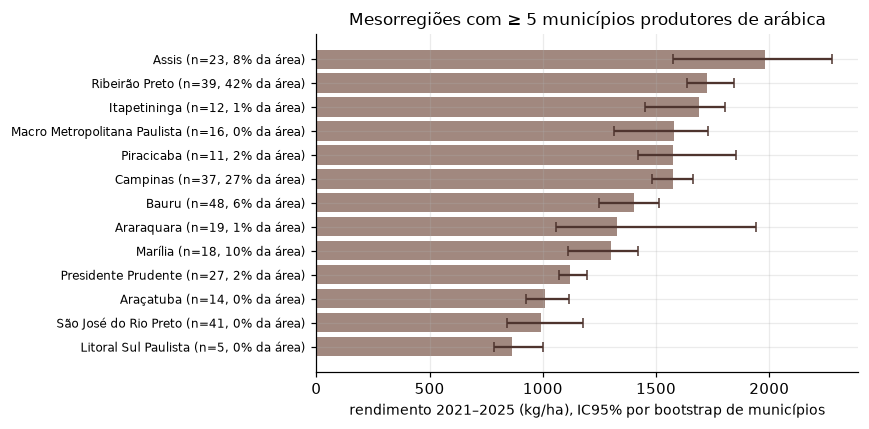

In [3]:
r = reg[reg.municípios >= 5].sort_values("rendimento (kg/ha)")
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(r))
ax.barh(y, r["rendimento (kg/ha)"], color="#a1887f", xerr=[r["rendimento (kg/ha)"] - r["IC95 inf"], r["IC95 sup"] - r["rendimento (kg/ha)"]], ecolor="#4e342e", capsize=3)
ax.set_yticks(y); ax.set_yticklabels([f"{i} (n={int(m)}, {p:.0f}% da área)" for i, m, p in zip(r.index, r.municípios, r["% da área paulista"])], fontsize=8)
ax.set_xlabel("rendimento 2021–2025 (kg/ha), IC95% por bootstrap de municípios"); ax.set_title("Mesorregiões com ≥ 5 municípios produtores de arábica")
plt.tight_layout(); plt.savefig(FIG / "08_regioes.png"); plt.show()

**Como ler:** barras = estimativa pontual; linhas = IC95%. **Intervalos que se sobrepõem** não permitem afirmar que uma região é "mais produtiva" que outra. Regiões com poucos municípios têm intervalos largos. **Resultado nesta execução:** as duas maiores regiões (Ribeirão Preto ≈1 725 kg/ha; Campinas ≈1 573) têm ICs que quase se tocam; Presidente Prudente (≈1 122), Araçatuba (≈1 011) e São José do Rio Preto (≈991) ficam **claramente abaixo**; Assis tem a maior estimativa (≈1 982), mas com IC largo (≈1 575–2 278), que **não** a separa de Ribeirão Preto. A legenda mostra quantos municípios e que fração da área cada região representa: **produtividade alta em área pequena** pesa pouco no estado.

### Altitude e produtividade (descritivo)
O arábica é cultivado em altitudes maiores (temperaturas mais amenas). Conferimos a associação **entre municípios**, usando a altitude do ponto da grade climática (NASA POWER, ~55 km) como aproximação — que **não é** a altitude real das lavouras.

In [4]:
m2 = mun.dropna(subset=["elev_m"])
rho, p = stats.spearmanr(m2.elev_m, 1000 * m2.t / m2.a)
bs = []
for _ in range(1000):
    s = m2.sample(len(m2), replace=True, random_state=int(rng.integers(1e9)))
    bs.append(stats.spearmanr(s.elev_m, 1000 * s.t / s.a)[0])
print(f"Spearman (altitude da célula × rendimento municipal 2021–25): ρ = {rho:.2f} (n = {len(m2)} municípios, p = {p:.3g}); IC95 bootstrap = [{np.percentile(bs, 2.5):.2f}, {np.percentile(bs, 97.5):.2f}]")

Spearman (altitude da célula × rendimento municipal 2021–25): ρ = 0.48 (n = 314 municípios, p = 9.03e-20); IC95 bootstrap = [0.40, 0.57]


**Como ler:** a correlação é entre **municípios** (n grande, mas vizinhos compartilham a mesma célula, então a independência efetiva é menor). O resultado é uma associação **positiva moderada** (ρ ≈ 0,48; IC95 ≈ 0,40–0,57). Mas **altitude é um proxy** de temperatura, solo, cultivar, tecnologia e histórico de manejo — **não** é o efeito de "subir a altitude". Não use isso para recomendar plantio em altitude X.

**Confiança na resposta 1:** **média** para o ranking das regiões grandes (muitos municípios, IC estreito); **baixa** para regiões pequenas. Resultado baseado em **estimativas administrativas** com repetição de valores (notebook 02).

## Pergunta 2 · Como a produção evoluiu?

Pico de produção: 1981 (1,218 mil t); 2025: 316 mil t (-74% vs. pico)
Área colhida: 908 mil ha (máx.) → 194 mil ha em 2025
Rendimento, média 5 anos: 1,287 kg/ha (1974–78) → 1,618 kg/ha (2021–25)


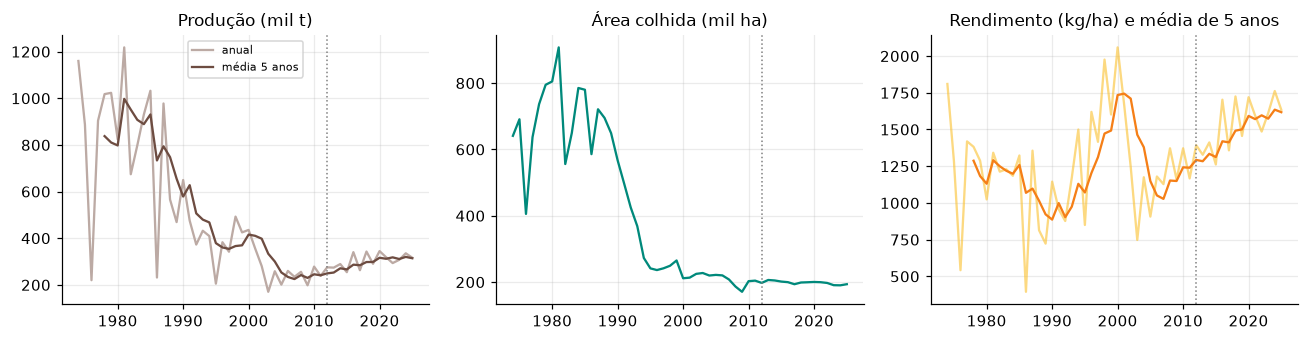

In [5]:
sp = q('''SELECT ano, quantidade_t/1e3 AS prod_kt, area_colhida_ha/1e3 AS area_kha, rendimento_kg_ha, valor_mil_reais/1e6 AS valor_bi
          FROM pam_uf WHERE uf='SP' AND especie='total' ORDER BY ano''')
sp["prod_5a"] = sp.prod_kt.rolling(5).mean(); sp["rend_5a"] = sp.rendimento_kg_ha.rolling(5).mean()
pico = sp.loc[sp.prod_kt.idxmax()]
print(f"Pico de produção: {int(pico.ano)} ({pico.prod_kt:,.0f} mil t); 2025: {sp.prod_kt.iloc[-1]:,.0f} mil t ({100*(sp.prod_kt.iloc[-1]/pico.prod_kt-1):.0f}% vs. pico)")
print(f"Área colhida: {sp.area_kha.max():,.0f} mil ha (máx.) → {sp.area_kha.iloc[-1]:,.0f} mil ha em 2025")
print(f"Rendimento, média 5 anos: {sp.rend_5a.dropna().iloc[0]:,.0f} kg/ha (1974–78) → {sp.rend_5a.iloc[-1]:,.0f} kg/ha (2021–25)")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(sp.ano, sp.prod_kt, color="#bcaaa4", label="anual"); ax[0].plot(sp.ano, sp.prod_5a, color="#6d4c41", label="média 5 anos"); ax[0].set_title("Produção (mil t)"); ax[0].legend(fontsize=7)
ax[1].plot(sp.ano, sp.area_kha, color="#00897b"); ax[1].set_title("Área colhida (mil ha)")
ax[2].plot(sp.ano, sp.rendimento_kg_ha, color="#fbc02d", alpha=.6); ax[2].plot(sp.ano, sp.rend_5a, color="#f57f17"); ax[2].set_title("Rendimento (kg/ha) e média de 5 anos")
for a in ax: a.axvline(2012, color="grey", ls=":", lw=1)
plt.tight_layout(); plt.savefig(FIG / "08_evolucao.png"); plt.show()

**Como ler:** a produção paulista **encolheu** desde o pico (impresso acima), puxada pela **queda da área**, enquanto o rendimento (média de 5 anos) **aumentou**: a lavoura que ficou é menor e, em média, mais produtiva. A linha pontilhada em 2012 marca o início da separação arábica/conilon — **antes dela a série é "total"**. A série de 5 anos é mais confiável que a comparação entre dois anos isolados (bienalidade).

**Concentração (arábica, 2012+):** a produção está em poucos municípios? Note que o número de municípios produtores **caiu** (362 → 263) e a fatia dos 10 maiores subiu de ≈40% para ≈48%.

In [6]:
c = q('''SELECT ano, cod_ibge, quantidade_t AS t FROM pam_municipio WHERE especie='arabica' AND ano >= 2012 AND quantidade_t > 0''')
rows = []
for ano, g in c.groupby("ano"):
    s = g.t.sort_values(ascending=False); sh = s / s.sum()
    rows.append({"ano": ano, "municípios produtores": len(g), "top-10 (% da produção)": 100 * sh.head(10).sum(), "HHI (0–10 000)": 10000 * (sh ** 2).sum()})
conc = pd.DataFrame(rows).set_index("ano"); conc.round(1)

,municípios produtores,top-10 (% da produção),HHI (0–10 000)
ano,,,
2012,362,39.90,232.80
2013,361,39.60,238.90
2014,342,41.80,259.90
2015,332,40.70,244.40
2016,325,47.20,306.70
2017,322,40.50,245.50
2018,316,47.30,320.10
2019,312,42.50,258.40
2020,313,47.70,318.70


**Como ler:** **HHI** (Herfindahl-Hirschman) = 10 000 × Σ *s<sub>i</sub>*², em que *s<sub>i</sub>* é a participação do município *i*. Ele varia de ≈0 (produção pulverizada) a 10 000 (um único município). Valores baixos (< 1 500 na convenção de mercados) indicam **baixa concentração municipal**. Atenção: mesmo com baixa concentração por município, a produção é **concentrada por região** (pergunta 1: ≈70% da área em duas mesorregiões).

**Confiança na resposta 2:** **alta** para o sentido da tendência de longo prazo (série oficial de 50 anos); **média** para atribuir causas (área, tecnologia, preço) — os dados não separam.

## Pergunta 3 · Qual a relação entre clima e produtividade?

Reproduzimos, de forma **compacta**, o núcleo do notebook 04: correlação de postos entre **anomalias** climáticas e de rendimento (município × ano), com IC por **bootstrap de anos** (a unidade independente é a safra, ~13, e não as 1 663 linhas).

In [7]:
FEATS = M.CLIMA
dd = q("select * from painel_cafe_arabica where elegivel_modelo").dropna(subset=FEATS + ["rendimento_kg_ha"]).copy()
dd["y_anom"] = dd.rendimento_kg_ha - dd.groupby("cod_ibge").rendimento_kg_ha.transform("mean")
for cf in FEATS: dd[cf + "_anom"] = dd[cf] - dd.groupby("cell_id")[cf].transform("mean")
anos = np.sort(dd.ano.unique()); by_year = {a: g for a, g in dd.groupby("ano")}
rows = []
for cf in FEATS:
    rho = stats.spearmanr(dd[cf + "_anom"], dd.y_anom)[0]
    bs = []
    for _ in range(300):
        s = pd.concat([by_year[a] for a in rng.choice(anos, len(anos), replace=True)])
        bs.append(stats.spearmanr(s[cf + "_anom"], s.y_anom)[0])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    rows.append({"feature": cf, "ρ": rho, "IC95 inf": lo, "IC95 sup": hi, "IC inclui 0?": lo < 0 < hi})
cl = pd.DataFrame(rows).set_index("feature")
print(f"{len(dd):,} linhas município-ano | {len(anos)} anos distintos ({anos.min()}–{anos.max()})")
cl.round(2)

1,663 linhas município-ano | 13 anos distintos (2013–2025)


,ρ,IC95 inf,IC95 sup,IC inclui 0?
feature,,,,
chuva_floracao,0.06,-0.05,0.16,True
tmean_floracao,0.09,-0.06,0.19,True
chuva_granacao,-0.01,-0.11,0.14,True
tmax_granacao,0.03,-0.09,0.14,True
chuva_12m_pre,-0.03,-0.12,0.10,True
dias_frio_inv_prev,0.04,-0.03,0.12,True


**Como ler:** onde `IC inclui 0? = True`, **não há evidência** de associação detectável com este *n* de anos. **Nesta execução, nenhuma das seis features tem IC que exclua 0** (|ρ| ≤ 0,09). Se algum IC excluísse 0, a associação seria de sinal conhecido e magnitude imprecisa, e só **descritiva**.

**O que NÃO concluir:**
- **Causalidade.** Um ρ distinto de zero não significa que "a chuva da florada aumenta o rendimento". Clima, bienalidade, manejo e preço variam juntos. (Nem a **ausência** de ρ prova que o clima não importa: geada e seca severas, que afetam muito, aparecem diluídas em médias de 55 km e em ~13 safras.)
- **Previsão a partir de correlação.** O notebook 06 mostra que adicionar clima **não** melhorou o erro de previsão frente à persistência.

**Interpretação agronômica (hipóteses, não resultados):** a florada (set–nov) é sensível a déficit hídrico e calor; o enchimento de grãos (dez–mar) exige água; o frio extremo do inverno pode danificar ramos. Estas são as **razões** de usar essas janelas; os dados deste projeto **não as confirmam nem refutam**.

**Confiança na resposta 3:** **baixa**. A resposta honesta é: "associações fracas ou indetectáveis no recorte, com forte confusão pela bienalidade".

## Pergunta 4 · É possível prever a produção de uma região?

Reexecutamos o backtest do notebook 06 (cenário A) e **agregamos por mesorregião**: produção prevista = Σ rendimento previsto × área de referência.

In [8]:
res = M.backtest(q("select * from painel_cafe_arabica"), "A")
p = res.preds.merge(q("select cod_ibge, mesorregiao from dim_municipio"), on="cod_ibge")
rows = []
for meso, g in p.groupby("mesorregiao"):
    if g.cod_ibge.nunique() < 8: continue
    a = g.groupby("ano").apply(lambda x: pd.Series({"obs": x.quantidade_t.sum(), **{m: (x[m] * x.area_ref).sum() / 1000 for m in ["xgboost", "media_lags", "naive_lag1"]}}))
    row = {"mesorregião": meso, "municípios": g.cod_ibge.nunique(), "produção média (t)": a.obs.mean()}
    for m in ["xgboost", "media_lags", "naive_lag1"]:
        row[f"WAPE {m} (%)"] = 100 * (a[m] - a.obs).abs().sum() / a.obs.sum()
    rows.append(row)
regp = pd.DataFrame(rows).set_index("mesorregião").sort_values("produção média (t)", ascending=False)
st = M.regional_production(res, ["xgboost", "media_lags", "naive_lag1"])
print("Estado (municípios elegíveis) — erro % absoluto médio por ano:", {m: round(st[f"{m}_erro_%"].abs().mean(), 1) for m in ["xgboost", "media_lags", "naive_lag1"]})
regp.round(1)

Estado (municípios elegíveis) — erro % absoluto médio por ano: {'xgboost': np.float64(6.9), 'media_lags': np.float64(7.7), 'naive_lag1': np.float64(14.0)}


,municípios,produção média (t),WAPE xgboost (%),WAPE media_lags (%),WAPE naive_lag1 (%)
mesorregião,,,,,
Ribeirão Preto,27,"133,740.90",13.30,15.70,27.00
Campinas,26,"81,107.00",5.30,4.30,4.40
Assis,12,"30,127.30",8.90,7.30,5.10
Marília,14,"28,154.20",13.60,10.60,14.50
Bauru,25,"16,837.70",8.10,4.00,5.10
Presidente Prudente,16,"5,213.40",20.40,18.70,20.30


**Como ler:** WAPE = Σ|previsto − observado| ÷ Σ observado, por mesorregião, ao longo de 2017–2025. **Compare com o `naive_lag1`**: se o XGBoost ou a média de lags não forem claramente melhores, o modelo não agrega valor sobre "repetir o ano passado". Regiões com poucos municípios têm WAPE mais instável.

**Resposta:** no **agregado do estado** (municípios elegíveis), o erro absoluto médio anual é ≈6,9% (XGBoost) e ≈7,7% (média de lags), **cerca da metade** dos ≈14,0% de "repetir o ano anterior". **Por mesorregião, a história é mais modesta:** a vantagem sobre o `naive_lag1` aparece só em Ribeirão Preto (WAPE ≈27% → ≈13–16%); em Campinas, Assis e Bauru o `naive_lag1` é **igual ou melhor** que o XGBoost, e a média de lags supera o XGBoost em 5 das 6 regiões listadas. Além disso: (i) os anos de safra **alta/baixa** continuam errados de forma sistemática (−14% a −17% em 2018 e 2024 no estado); (ii) o **clima da safra futura** não é conhecido na data de corte.

**Confiança na resposta 4:** **média** para a ordem de grandeza do **estado** (erro ≈7%); **baixa a média** por região (WAPE entre ≈4% e ≈27% conforme região e modelo, sem vencedor consistente); **baixa** para anos de ruptura (geada, seca) e para municípios isolados.

## Aritmética de cenários: sensibilidade a produtividade e preço

Receita bruta = produtividade × área × preço. Usamos como **ponto de partida** os valores **observados** do estado em 2025 (PAM): preço implícito = valor da produção ÷ quantidade. A grade mostra a **variação relativa** da receita; **não** calcula margem (não há dados de custo neste projeto).

In [9]:
u = q("SELECT area_colhida_ha, quantidade_t, valor_mil_reais, rendimento_kg_ha FROM pam_uf WHERE uf='SP' AND especie='total' AND ano = 2025").iloc[0]
preco_saca = u.valor_mil_reais * 1000 / (u.quantidade_t * 1000 / 60)
print(f"SP 2025 (PAM, total): rendimento {u.rendimento_kg_ha:,.0f} kg/ha | preço implícito ≈ R$ {preco_saca:,.0f}/saca de 60 kg | valor da produção R$ {u.valor_mil_reais/1e6:,.1f} bi")
var = [-0.2, -0.1, 0, 0.1, 0.2]
grade = pd.DataFrame({f"preço {int(100*dp):+d}%": [100 * ((1 + dy) * (1 + dp) - 1) for dy in var] for dp in var}, index=[f"produtividade {int(100*dy):+d}%" for dy in var])
print("\nVariação da receita bruta (%):"); display(grade.round(1))

SP 2025 (PAM, total): rendimento 1,634 kg/ha | preço implícito ≈ R$ 2,034/saca de 60 kg | valor da produção R$ 10.7 bi

Variação da receita bruta (%):


,preço -20%,preço -10%,preço +0%,preço +10%,preço +20%
produtividade -20%,-36.00,-28.00,-20.00,-12.00,-4.00
produtividade -10%,-28.00,-19.00,-10.00,-1.00,8.00
produtividade +0%,-20.00,-10.00,0.00,10.00,20.00
produtividade +10%,-12.00,-1.00,10.00,21.00,32.00
produtividade +20%,-4.00,8.00,20.00,32.00,44.00


**Como ler:** a receita varia **multiplicativamente**: −10% de produtividade e −10% de preço dão −19% (não −20%). Na prática, **produtividade e preço do mercado brasileiro tendem a se mover em sentidos opostos** quando o choque é climático generalizado (uma geada reduz a oferta e eleva o preço), o que daria uma **proteção natural** parcial — **mas os dados deste projeto não demonstram** essa relação (notebook 05: correlação entre variação de produção e de preço indistinguível de zero com *n* ≈ 24). Já um choque **local** (granizo na sua fazenda) não é compensado por preço.

**Margem:** com custo por hectare *C* (informado por você), margem/ha = *Y*·*P*/60 − *C*, com *Y* em kg/ha e *P* em R$/saca. Como *C* é praticamente fixo, **a margem é bem mais sensível que a receita**: uma queda de 10% na receita pode eliminar uma fração muito maior da margem. Calcule com o **seu** custo; este projeto **não inventa** números de custo.

## Recomendações

| # | Recomendação | Base | Confiança |
|---|---|---|---|
| 1 | Prefira uma **média de safras recentes** a repetir só o último ano como referência esperada | notebooks 05 e 06: médias superam o `naive` no estado e no município (testamos 2 lags; por região o `naive_lag1` às vezes empata) | média |
| 2 | **Planeje por intervalos**, não por ponto: erro regional típico de ≈5–25% (WAPE) conforme região; bienalidade inclusa | notebook 06 e pergunta 4; cobertura empírica ≈ 65–87% por ano | média |
| 3 | Não decida por **clima de grade** sozinho; use dados da propriedade (estação local, solo, idade/poda) | notebooks 04, 06 | alta (na limitação) |
| 4 | Para prever sua safra, registre **produtividade própria por talhão**: lags próprios são o preditor mais forte | notebook 06 (importância dos lags) | média |
| 5 | Trate a comparação **entre regiões** com os ICs (pergunta 1); diferenças dentro do intervalo não são evidência | pergunta 1 | alta |
| 6 | Para este volume, **pandas/Polars/DuckDB bastam**; não adote Spark sem necessidade comprovada | notebook 07 | alta |

## Limitações (resumo)

- **Dados oficiais são estimativas** (PAM) com valores repetidos; erros de medição **atenuam** relações e dificultam previsão.
- **Poucos anos independentes** (≈13): intervalos largos; qualquer ranking de modelos é frágil.
- **Clima de reanálise (NASA POWER, ~55 km)** não vê geadas locais, relevo ou microclima; a altitude da célula **não** é a da lavoura.
- **Sem manejo, poda, cultivar, idade do cafezal nem custos.** O que parece "efeito do clima" pode ser manejo.
- **Preços:** apenas séries com metodologia confirmada; INMET indisponível por falha de TLS (não contornada); licenças do Banco Mundial e BCB não confirmadas — por isso o lago de dados **não é redistribuído**.
- **Escopo SP, arábica.** Conclusões não se transferem a Minas Gerais, Espírito Santo ou conilon sem refazer o trabalho.

## Exercícios
1. Refaça a pergunta 1 por **microrregião** e verifique quais diferenças sobrevivem aos intervalos de confiança.
2. Troque o período (2016–2020 × 2021–2025): o ranking das mesorregiões se mantém? Isso indica estabilidade estrutural ou ruído?
3. Para um talhão de 50 ha, com rendimento e custo seus, construa a grade de margem (não só de receita) e identifique o **rendimento de equilíbrio**.
4. Calcule o HHI por **mesorregião** em vez de por município e compare com o resultado municipal.
5. Escreva, em 5 linhas, o que **não** pode ser concluído a partir deste notebook para um banco avaliando crédito rural.